# Report · Dự đoán khả năng mua hàng trên website

**Thành viên**

- Nguyễn Duy Thuận (25TX810025)
- Đoàn Thị Mỹ Thiện (25TX810023)
- Phạm Văn Bình (25TX610001)

## Abstract

Hiểu khả năng mua hàng của khách có thể giúp website ưu tiên phân tích các phiên có tín hiệu giao dịch. Đồ án nghiên cứu khả năng xếp hạng và phân loại phiên từ dữ liệu tổng hợp của bộ Online Shoppers Purchasing Intention. Bộ dữ liệu có 12.330 phiên, trong đó 15,47% phiên có mua hàng. Cấu hình chính giữ lại 16 đặc trưng đầu vào vì thời điểm có sẵn của PageValues chưa được xác minh.

Dữ liệu được chia phân tầng thành 9.864 phiên huấn luyện và 2.466 phiên kiểm tra. Năm mô hình dùng chung năm fold validation. Các bước tiền xử lý được học trong từng fold. Random Forest được chọn theo Average Precision trung bình trên validation. Ngưỡng phân loại được xác định bằng F1 của lớp mua trên dự đoán out-of-fold từ train.

Trên tập kiểm tra, Random Forest đạt Average Precision 0,3542 và ROC-AUC 0,7610. Tại ngưỡng đã chốt, mô hình phát hiện 223 trong 382 phiên mua và báo nhầm 513 phiên không mua. Precision đạt 30,30% và Recall đạt 58,38%. Kiểm tra bổ sung theo nhóm feature giống nhau giữ nguyên thứ hạng giữa Random Forest và Logistic Regression. Kết quả mô tả hiệu năng offline trên dữ liệu phiên đã tổng hợp. Việc áp dụng cho website khác hoặc dự đoán sớm trong phiên cần dữ liệu và đánh giá riêng.

## Introduction

Đồ án đánh giá tín hiệu mua hàng từ đặc trưng đã tổng hợp trong một phiên. Câu hỏi chính là mô hình nào xếp hạng tốt nhất các phiên mua, và ngưỡng chọn trên train tạo ra mức bỏ sót và báo nhầm nào trên test. Kết quả giúp mô tả sự đánh đổi giữa Precision và Recall của lớp mua trong bối cảnh offline.

## Data

Dữ liệu đến từ UCI [1]. Mỗi hàng là một phiên, 17 feature gốc và nhãn `Revenue`. Có 0 giá trị thiếu. Giữ nguyên 125 dòng trùng hoàn toàn sau lần xuất hiện đầu tiên vì CSV thiếu mã phiên để phân biệt các trường hợp cùng giá trị tổng hợp. Xem [bảng biến](../data/README.md).

**Bảng 1. Quy mô dữ liệu và phân bố lớp mua**

| Tập | Số phiên | Phiên mua | Tỷ lệ mua |
|---|---:|---:|---:|
| Toàn bộ | 12.330 | 1.908 | 15,47% |
| Train | 9.864 | 1.526 | 15,47% |
| Test | 2.466 | 382 | 15,49% |

EDA trên train ghi trung vị 29 trang sản phẩm và 1.120,8 giây ở nhóm mua, so với 16 trang và 511,3 giây ở nhóm không mua. Khoảng phân vị 25%–75% của số trang sản phẩm là 15–57 cho nhóm mua và 6–35 cho nhóm không mua, nên hai phân bố vẫn chồng lấn.

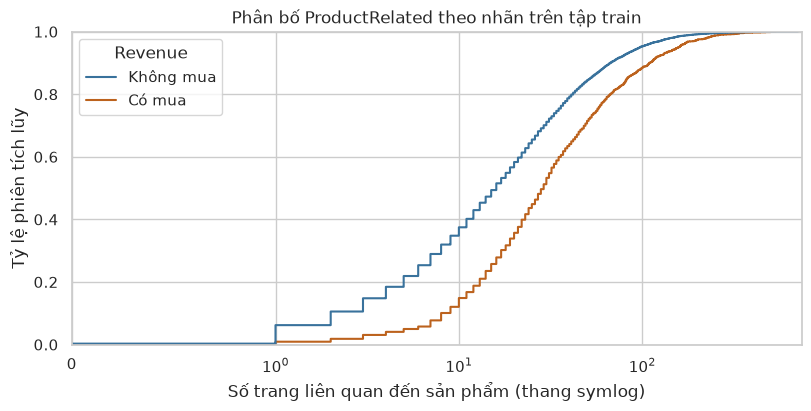

**Hình 1. Phân bố tích lũy số trang sản phẩm theo nhãn trên tập train**

## Methods

Chia phân tầng 80/20 với seed 42 và cố định vị trí dòng. Dùng cùng 5 fold `StratifiedKFold` trên train. Pipeline one-hot encode 7 cột phân loại, kể cả các mã số như `Browser`, `Region` và `TrafficType`. Logistic Regression và kNN thêm scaling cho biến số. Mỗi bước fit học từ phần train của fold.

Cấu hình chính dùng 16 feature, tách `Revenue` làm nhãn và loại `PageValues`. Chạy DummyClassifier, Logistic Regression, kNN, Decision Tree và Random Forest. Chọn theo AP trung bình trên validation [2]. Random Forest cố định dùng 100 cây, độ sâu tối đa 12, tối thiểu 5 mẫu/lá, seed 42 và `class_weight=None`. Trong thí nghiệm bổ sung, so sánh 12 cấu hình bằng nested grouped CV. Fit ở từng fold ngoài dùng 4 fold nhóm nội bộ để chọn siêu tham số, sau đó chấm trên fold ngoài. [Notebook huấn luyện](../notebooks/02_training.ipynb) · [Kiểm tra độ ổn định](../notebooks/04_robustness.ipynb)

Chọn ngưỡng 0,20964924233624288 theo F1 lớp mua trên các dự đoán out-of-fold. Khi đồng hạng, lấy ngưỡng cao nhất. F1 OOF tại ngưỡng này là 0,4239, so với 0,0405 tại ngưỡng 0,5. Chốt mô hình, feature, tham số và ngưỡng trước bước đánh giá test [3]. AP và ROC-AUC dùng điểm mua. Precision, Recall, F1 và confusion matrix dùng nhãn tại ngưỡng đã chốt.

## Experiments, Results and Discussion

**Bảng 2. So sánh Average Precision trên cùng 5 fold validation**

| Mô hình | AP trung bình | Độ lệch chuẩn |
|---|---:|---:|
| Random Forest | 0,3762 | 0,0294 |
| Logistic Regression | 0,3232 | 0,0196 |
| Decision Tree | 0,3180 | 0,0155 |
| kNN | 0,2839 | 0,0217 |
| DummyClassifier | 0,1547 | 0,0002 |

**Bảng 3. Kết quả test của mô hình cố định**

AP là độ đo chính vì lớp mua chiếm tỷ lệ thấp.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "project_model.py").is_file():
    project_root = project_root.parent
if not (project_root / "project_model.py").is_file():
    raise FileNotFoundError("Hãy chạy notebook từ thư mục gốc, notebooks/ hoặc submission/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import json

import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)

from project_model import THRESHOLD, load_train, make_forest

X_train, y_train = load_train()
data = pd.read_csv(project_root / "data/online_shoppers_intention.csv")
split = json.loads((project_root / "data/split_indices.json").read_text(encoding="utf-8"))
test = data.iloc[split["test_indices"]]
X_test, y_test = test[X_train.columns], test["Revenue"]
model = make_forest(X_train.columns).fit(X_train, y_train)
scores = model.predict_proba(X_test)[:, 1]
labels = scores >= THRESHOLD
matrix = confusion_matrix(y_test, labels, labels=[False, True])
print(f"TN={matrix[0,0]}, FP={matrix[0,1]}, FN={matrix[1,0]}, TP={matrix[1,1]}")
display(pd.Series({
    "Average Precision": average_precision_score(y_test, scores),
    "ROC-AUC": roc_auc_score(y_test, scores),
    "Precision (mua)": precision_score(y_test, labels),
    "Recall (mua)": recall_score(y_test, labels),
    "F1 (mua)": f1_score(y_test, labels),
}, name="Điểm test").to_frame().round(4))

TN=1571, FP=513, FN=159, TP=223


,Điểm test
Average Precision,0.3542
ROC-AUC,0.7610
Precision (mua),0.3030
Recall (mua),0.5838
F1 (mua),0.3989


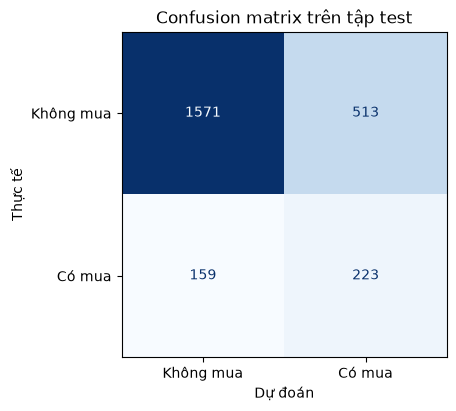

**Hình 2. Confusion matrix của Random Forest tại ngưỡng 0,20965 trên tập test**

Baseline luôn đoán không mua đạt Accuracy 84,51% và bỏ sót cả 382 phiên mua. Độ chính xác tổng thể cao trong trường hợp này phản ánh tỷ lệ lớp đa số. Vì vậy, bảng kết quả tập trung vào chất lượng xếp hạng và nhận diện lớp mua. Random Forest phát hiện 223 phiên mua, bỏ sót 159 và báo nhầm 513. Tỷ lệ mua cao hơn có liên hệ với mức tương tác, nhưng một số phiên tương tác nhiều vẫn không mua. Ví dụ, dòng 9.576 xem 337 trang sản phẩm và nhận điểm 0,6187 nhưng không mua. Dòng 2.392 có mua sau khi xem 3 trang nhưng nhận điểm 0,0180. [Notebook đánh giá](../notebooks/03_evaluation.ipynb)

### Overfitting và độ bất định

Trên cùng 5 fold phân tầng theo nhóm, AP trung bình của Random Forest cố định là **0,6825 trên phần fit** và **0,3828 trên validation**. Khoảng cách cho thấy điểm trên dữ liệu đã fit đánh giá quá lạc quan khả năng khái quát. Quy trình tinh chỉnh 12 cấu hình đạt 0,38083 trên cùng các fold ngoài, so với 0,38277 của cấu hình cố định.

Có 29 phiên test có vector trùng train, đều không mua. Khi bỏ tạm 29 phiên trong kiểm tra độ nhạy với mô hình và ngưỡng cố định, AP vẫn làm tròn 0,3542, Precision và Recall giữ nguyên. Bảng chính dùng đủ 2.466 phiên. Lấy mẫu có hoàn lại 2.000 lần từ 2.454 nhóm test với mô hình và ngưỡng cố định. Giả định các nhóm độc lập. Kết quả cho khoảng bootstrap 95% **0,3101–0,4053** đối với AP, **26,94–33,65%** đối với Precision và **53,20–63,23%** đối với Recall [4].

Thêm `PageValues` làm AP trên grouped CV tăng từ 0,3828 lên 0,7427. Cần xác minh cách tính và thời điểm có feature để kết luận về leakage. Phép so sánh có và không có PageValues dùng train. [Notebook kiểm tra bổ sung](../notebooks/06_model_review.ipynb) · [Phụ lục thử nghiệm bổ sung](#phu-luc)

**Bảng 4. Average Precision trên phần fit và validation theo từng fold nhóm**

In [2]:
from IPython.display import Markdown
from sklearn.model_selection import StratifiedGroupKFold

groups = X_train.groupby(list(X_train.columns), sort=False, dropna=False).ngroup()
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
fold_rows = []
for fold, (fit, val) in enumerate(folds.split(X_train, y_train, groups), start=1):
    assert not groups.iloc[fit].isin(groups.iloc[val]).any()
    fold_model = make_forest(X_train.columns).fit(X_train.iloc[fit], y_train.iloc[fit])
    fold_rows.append({
        "Fold": fold,
        "AP phần fit": average_precision_score(y_train.iloc[fit], fold_model.predict_proba(X_train.iloc[fit])[:, 1]),
        "AP validation": average_precision_score(y_train.iloc[val], fold_model.predict_proba(X_train.iloc[val])[:, 1]),
    })

fold_scores = pd.DataFrame(fold_rows).set_index("Fold")
fold_scores.loc["Trung bình"] = fold_scores.mean()
display(fold_scores.round(4))

seen = pd.MultiIndex.from_frame(X_test).isin(pd.MultiIndex.from_frame(X_train))
unique_to_test = ~seen
assert y_test[seen].sum() == 0
display(Markdown("**Bảng 5. Độ nhạy với các dòng test trùng vector train**"))
print(f"Bỏ tạm {seen.sum()} dòng trùng vector và giữ nguyên mô hình, ngưỡng.")
display(pd.DataFrame([
    {"Phạm vi": name, "Số phiên": len(actual), "AP": average_precision_score(actual, proba),
     "Precision": precision_score(actual, proba >= THRESHOLD),
     "Recall": recall_score(actual, proba >= THRESHOLD)}
    for name, actual, proba in [
        ("Toàn bộ test", y_test, scores),
        ("Test sau khi bỏ tạm dòng trùng train", y_test[unique_to_test], scores[unique_to_test]),
    ]
]).round(6))

,AP phần fit,AP validation
Fold,,
1,0.6844,0.3708
2,0.6848,0.3944
3,0.6836,0.3955
4,0.6838,0.3489
5,0.6762,0.4043
Trung bình,0.6825,0.3828


**Bảng 5. Độ nhạy với các dòng test trùng vector train**

Bỏ tạm 29 dòng trùng vector và giữ nguyên mô hình, ngưỡng.


,Phạm vi,Số phiên,AP,Precision,Recall
0,Toàn bộ test,2466,0.354242,0.302989,0.58377
1,Test sau khi bỏ tạm dòng trùng train,2437,0.354243,0.302989,0.58377


## Conclusion

Random Forest dẫn đầu trên validation và phát hiện 58,38% phiên mua trong tập test. AP là 0,3542. Khả năng ứng dụng phụ thuộc vào chi phí của 513 báo nhầm và 159 bỏ sót tại ngưỡng đã chọn. Để đánh giá dự đoán sớm, cần log sự kiện theo thời gian để tái tạo feature tại thời điểm dự đoán. Khả năng khái quát sang website khác cần được đánh giá trên nguồn dữ liệu độc lập.

## Contributions

**Bảng 6. Sản phẩm và bằng chứng trong repo**

| Đầu việc | Bằng chứng đã kiểm tra |
|---|---|
| Dữ liệu, split và EDA | [Notebook 01](../notebooks/01_eda.ipynb) và [data/README.md](../data/README.md) |
| Pipeline, đánh giá và kiểm tra bổ sung | [Notebook 02](../notebooks/02_training.ipynb), [03](../notebooks/03_evaluation.ipynb), [04](../notebooks/04_robustness.ipynb), [05](../notebooks/05_learning_curve.ipynb) và [06](../notebooks/06_model_review.ipynb) |
| Tổng hợp và trình bày | Bảng 3–5 trong notebook này và [slide tiếng Anh](Presentation.pptx) |

**Bảng 7. Công việc phụ trách theo thành viên**

| Họ tên | MSSV | Công việc phụ trách |
|---|---|---|
| Nguyễn Duy Thuận | 25TX810025 | Chia và lưu train/test, xây dựng pipeline tiền xử lý, huấn luyện và so sánh năm mô hình. Chọn Random Forest theo điểm validation và chọn ngưỡng từ dự đoán out-of-fold trên train. Đánh giá test, phân tích lỗi, tổng hợp báo cáo và chuẩn bị câu hỏi kỹ thuật. Trình bày slide 1, 3, 4, 7 và 8. |
| Đoàn Thị Mỹ Thiện | 25TX810023 | Đối chiếu nguồn UCI, số phiên, tỷ lệ mua và số liệu EDA giữa notebook 01 với slide 2. Giải thích số trang sản phẩm và thời gian xem của hai nhóm. Trình bày slide 2. |
| Phạm Văn Bình | 25TX610001 | Đối chiếu bảng kết quả test và confusion matrix giữa Report và slide 5–6. Giải thích số phiên mua phát hiện đúng, bỏ sót và báo nhầm. Bấm giờ diễn tập, hỗ trợ ghi và kiểm tra video. Trình bày slide 5–6. |

<a id="phu-luc"></a>

## Phụ lục · Thử nghiệm bổ sung trên train

Các thử nghiệm sau dùng 9.864 phiên train. Kết quả test ở Bảng 3 áp dụng cho cấu hình và ngưỡng đã chốt ở tuần 3. [Notebook phân tích bổ sung](../notebooks/04_robustness.ipynb)

### Kiểm tra với grouped cross-validation

Gom các phiên có cùng bộ 16 feature thành 9.773 nhóm. Có 61 nhóm chứa từ hai phiên trở lên. Với `StratifiedKFold`, mỗi fold có từ 21 đến 33 dòng validation trùng vector với phần fit. Với `StratifiedGroupKFold`, số đó bằng 0 ở cả năm fold.

**Bảng 8. AP khi chia fold thông thường và theo nhóm**

| Mô hình | AP với 5 fold phân tầng | AP với 5 fold phân tầng theo nhóm |
|---|---:|---:|
| Random Forest | 0,3762 ± 0,0294 | 0,3828 ± 0,0203 |
| Logistic Regression | 0,3232 ± 0,0196 | 0,3251 ± 0,0158 |

Random Forest vẫn dẫn đầu trên bộ fold theo nhóm. Chênh lệch AP giữa hai cách chia có thể phản ánh việc thành phần từng fold thay đổi.

### Đánh đổi giữa Precision và Recall

Trên dự đoán out-of-fold theo nhóm của Random Forest cố định, đặt mục tiêu minh họa Precision ít nhất 40% rồi chọn ngưỡng có Recall cao nhất thỏa mốc này. Notebook lưu đường Precision–Recall và vị trí cả hai ngưỡng.

**Bảng 9. Precision, Recall và số lỗi của hai ngưỡng trên train**

| Phương án | Ngưỡng | Precision | Recall | F1 | FP | FN |
|---|---:|---:|---:|---:|---:|---:|
| Ngưỡng tuần 3 | 0,209649 | 32,21% | 61,99% | 0,4239 | 1.991 | 580 |
| Ưu tiên Precision | 0,275864 | 40,11% | 38,14% | 0,3910 | 869 | 944 |

Trên các dự đoán OOF này, ngưỡng cao hơn giảm 1.122 báo nhầm và bỏ sót thêm 364 phiên mua. Mức Precision 40,11% được đo trên cùng dự đoán OOF dùng để chọn ngưỡng. Đây là một phương án để minh họa đánh đổi, còn ngưỡng báo cáo test vẫn là ngưỡng tuần 3.

### Tinh chỉnh Random Forest

Thử 12 tổ hợp `max_depth`, `min_samples_leaf` và `class_weight` với nested grouped CV. GridSearchCV chọn theo AP qua 4 fold trong, sau đó cấu hình được đánh giá trên fold ngoài. Trên cùng 5 fold ngoài, AP trung bình là **0,38277** đối với Random Forest cố định và **0,38083** đối với quy trình tinh chỉnh. Chênh lệch trung bình theo cặp là **−0,00193**.

Khi tìm trên toàn bộ train, ứng viên tốt nhất bỏ giới hạn độ sâu, dùng `min_samples_leaf=5` và `class_weight=None`, với AP chọn cấu hình 0,38332. Kết quả trên các fold ngoài chưa cho thấy tinh chỉnh cải thiện AP. Vì vậy, báo cáo giữ cấu hình Random Forest ban đầu cho kết luận chính.

### Learning curve theo nhóm

Giữ nguyên các fold validation theo nhóm và cấu hình Random Forest của tuần 3. Trong mỗi fold, tăng dần tỷ lệ nhóm dùng để fit từ 25% lên 100%. Các dòng cùng nhóm được lấy cùng nhau và tập fit nhỏ nằm trong tập fit lớn hơn.

**Bảng 10. Learning curve trên các fold nhóm**

| Tỷ lệ nhóm fit | Số phiên fit trung bình | AP trung bình ± độ lệch chuẩn |
|---:|---:|---:|
| 25% | 1.972,6 | 0,35310 ± 0,02233 |
| 50% | 3.942,2 | 0,37836 ± 0,02889 |
| 75% | 5.917,0 | 0,37779 ± 0,02338 |
| 100% | 7.891,2 | 0,38277 ± 0,02026 |

AP tăng rõ nhất từ 25% lên 50% nhóm. Từ 50% đến 100%, mức tăng trung bình là 0,00441 và điểm ở mốc 75% thấp hơn nhẹ so với 50%. Đây là kết quả của một cách lấy mẫu lồng nhau trong 5 fold. Hiệu năng với lượng dữ liệu vượt ngoài các mốc đã thử vẫn chưa được xác minh. [Notebook learning curve](../notebooks/05_learning_curve.ipynb)

### Kiểm tra bộ feature và mô hình boosting

Dùng cùng 5 fold theo nhóm trên train và tính AP trung bình qua fold. Mỗi fold dùng nhóm xác định từ 16 feature chính cho mọi cấu hình.

**Bảng 11. Đối chiếu bộ feature và HistGradientBoosting**

| Cấu hình | AP trung bình ± độ lệch chuẩn |
|---|---:|
| Random Forest · 16 feature chính | 0,38277 ± 0,02026 |
| Random Forest · thêm `PageValues` | 0,74265 ± 0,01810 |
| Random Forest · 8 biến ngữ cảnh | 0,26739 ± 0,01231 |
| HistGradientBoosting · 16 feature chính | 0,35902 ± 0,02126 |

`PageValues` là chỉ số giá trị trang liên quan đến giao dịch. Mức tăng AP cho thấy mô hình có thể khai thác mạnh thông tin của cột này. Để xác định có leakage hay không, cần biết giá trị được tính từ dữ liệu của giai đoạn nào và có sẵn khi dự đoán hay chưa. Cấu hình báo cáo chính dùng 16 feature vì thời điểm có sẵn của `PageValues` chưa được xác minh. [Mô tả dữ liệu UCI](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)

Bộ 8 biến ngữ cảnh gồm `Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`, `Weekend` và `SpecialDay`. So sánh này đo tác động của việc bỏ các biến tổng hợp hành vi. Đánh giá dự đoán sau ba lượt xem trang cần timestamp và chuỗi sự kiện trong phiên để dựng feature tại thời điểm đó. CSV hiện tại chỉ có dữ liệu tổng hợp theo phiên. [Nghiên cứu về dự đoán sớm trong phiên](https://link.springer.com/article/10.1007/s12525-020-00448-x)

Cấu hình HistGradientBoosting được thử với 100 vòng boosting, `learning_rate=0.1` và `max_leaf_nodes=31`, dùng hỗ trợ biến phân loại theo dtype. Cấu hình này có AP thấp hơn Random Forest trên cùng fold. Kết luận giới hạn ở cấu hình đã thử. [Notebook so sánh](../notebooks/06_model_review.ipynb) · [Tài liệu HistGradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html)

### Calibration của điểm mua

So sánh điểm Random Forest gốc với điểm sau calibration sigmoid. Bộ hiệu chỉnh được học trong 4 fold nhóm nội bộ của từng fold ngoài. Bảng dưới tính trên dự đoán OOF của 5 fold ngoài. Baseline dùng tỷ lệ phiên mua của phần fit cho mọi phiên validation trong fold tương ứng.

**Bảng 12. Calibration trên dự đoán out-of-fold**

| Phương án | Brier loss ↓ | Log loss ↓ |
|---|---:|---:|
| Random Forest gốc | 0,11315 | 0,36059 |
| Calibration sigmoid | 0,11361 | 0,36560 |
| Tỷ lệ mua phần fit | 0,13077 | 0,43078 |

Ở nhóm điểm cao nhất của Random Forest gốc, điểm trung bình là 33,10% và tỷ lệ mua quan sát là 36,64%. Sau sigmoid, các số tương ứng ở nhóm điểm cao nhất là 38,27% và 36,59%. Sigmoid thu hẹp chênh lệch tuyệt đối ở nhóm này, nhưng cả hai loss tính trên toàn bộ OOF đều tăng nhẹ. Demo dùng điểm gốc để xếp hạng và gán nhãn tại ngưỡng tuần 3. [Biểu đồ calibration](../notebooks/06_model_review.ipynb) · [Tài liệu hiệu chỉnh xác suất](https://scikit-learn.org/stable/modules/calibration.html)

## References

1. Sakar, C. và Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. [DOI 10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q)
2. Saito, T. và Rehmsmeier, M. (2015). *The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets*. PLOS ONE. [DOI 10.1371/journal.pone.0118432](https://doi.org/10.1371/journal.pone.0118432)
3. scikit-learn. *Tuning the decision threshold for class prediction*. [Tài liệu](https://scikit-learn.org/stable/modules/classification_threshold.html)
4. SciPy. *Bootstrap confidence intervals*. [Tài liệu](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)